# Quantum campaign targeting: walkthrough

This notebook runs the whole pipeline once and then looks at each stage: the Stage 1 classifiers, the Stage 2 QUBO and QAOA, the Stage 3 circuit, and the error propagation. It uses the same code as `python run_pipeline.py`. The report with the full discussion is `README.md`.

In [1]:
import shutil, sys, warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "run_pipeline.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 80)
import run_pipeline
from campaign import config, qaoa, qubo, stage3, hardware
from campaign.models import feature_map_circuit

## Run the pipeline

One call. Results go to a scratch folder (`notebook_run/`, deleted at the end) so that the committed files stay as they are; the last section compares the two.

In [2]:
out = Path("notebook_run")
run = run_pipeline.main(out)
s1, kernel, s2, s3, prop = run["stage1"], run["kernel"], run["stage2"], run["stage3"], run["propagation"]

[   0.1s] data: 300 training rows (35 subscribers), 100 test rows


[  23.0s] stage 1: submitted model = hybrid, CV PR-AUC 0.277, Brier 0.1008


[  23.9s] stage 1: kernel entries from the overlap circuit, mean abs error 0.0016 (ideal shots)


[  87.2s] stage 2: selected C0031,C0079,C0081,C0318,C0005,C0170 | value 24.5334 | cost 15/25 | capacity 12/22 | gap to brute force 0.00e+00


[ 120.5s] stage 3: P(at least 3 of 6) quantum 0.338246 | exact 0.338495 | Monte Carlo 0.338159


[ 130.3s] error propagation: 200 refits, P(at least 3) 5th to 95th percentile 0.034 to 0.259


[ 131.3s] files written to notebook_run


## Stage 1: subscription prediction

Cross-validation on the 300 training customers only (5 folds, 3 repeats, the same folds for every model). The submitted model is the hybrid: the 50/50 average of logistic regression and the quantum kernel classifier.

In [3]:
columns = ["model", "params", "roc_auc", "pr_auc", "precision_at_10", "recall_at_10", "brier", "log_loss", "ece", "calibration_slope", "submitted"]
s1.cv_table[s1.cv_table["finalist"]][columns].round(4)

,model,params,roc_auc,pr_auc,precision_at_10,recall_at_10,brier,log_loss,ece,calibration_slope,submitted
3,logistic,C=0.3,0.6199,0.2839,0.1867,0.2667,0.1005,0.3544,0.0304,0.5869,False
32,quantum_kernel,"reducer=pls, reps=2, bandwidth=0.1, C=0.1",0.5745,0.2279,0.1733,0.2476,0.1034,0.3600,0.0189,0.5298,False
50,rbf_kernel,"reducer=pls, bandwidth=0.1, C=0.1",0.5748,0.2662,0.1600,0.2286,0.1035,0.3613,0.0276,0.2135,False
59,boosting,,0.5851,0.2453,0.1867,0.2667,0.1076,0.3952,0.0638,0.2640,False
60,hybrid,"weight=0.5, logistic={'C': 0.3}, quantum_kernel={'reducer': 'pls', 'reps': 2...",0.6205,0.2771,0.2067,0.2952,0.1008,0.3508,0.0167,0.8764,True


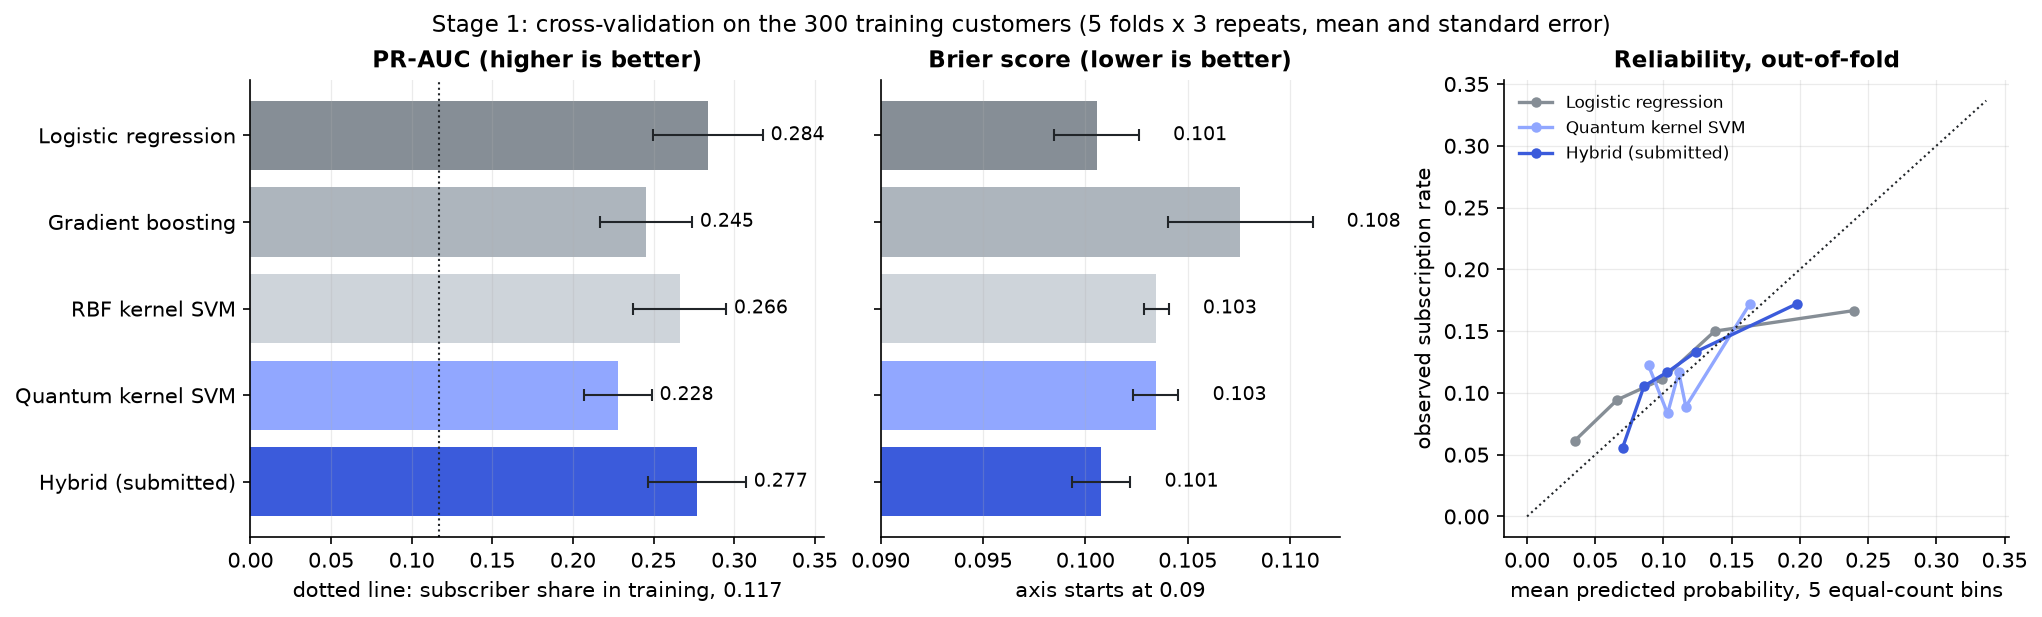

In [4]:
display(Image(filename=str(out / "results" / "figures" / "stage1_cross_validation.png")))

The quantum part of Stage 1 is the feature map below (6 qubits). A kernel entry is the squared overlap of two such states. The next table re-estimates a few entries by running the overlap circuit with shots.

In [5]:
quantum = s1.model.quantum_
print(feature_map_circuit(quantum.n_qubits, quantum.reps).draw(fold=140))

   ┌───┐┌───────────┐                                          ┌───┐         ┌───────────┐                    »
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──┤ H ├─────────┤ P(2*x[0]) ├────────────────────»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐└───┘         └───────────┘               ┌───┐»
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──■────────────────────────────────────■──┤ H ├»
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐┌──────────────────────────────┐┌─┴─┐└───┘»
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├┤ P((-π + x[1])*(-π + x[2])*2) ├┤ X ├──■──»
   ├───┤├───────────┤                                          └───┘└──────────────────────────────┘└───┘┌─┴─┐»
3: ┤ H ├┤ P(2*x[3]) ├────────────────────────────────────────────────────────────────────────────────────┤ X ├»
   ├───┤├───────────┤                                                                                   

In [6]:
kernel["pairs"].round(4)

,train_row_a,train_row_b,exact,ideal_shots,noisy_shots
0,26,232,0.0152,0.0154,0.0170
1,131,129,0.0684,0.0703,0.0588
2,209,25,0.4009,0.4019,0.3068
3,28,157,0.3317,0.3306,0.2411
4,219,228,0.1758,0.1713,0.1295
5,153,235,0.0051,0.0048,0.0095
6,251,135,0.2668,0.2726,0.2064
7,110,54,0.0129,0.0145,0.0128
8,193,233,0.2304,0.2317,0.1819
9,163,246,0.0016,0.0010,0.0034


Test predictions, ranked high to low (ties to the lower `customer_id`). The first ten go to Stage 2.

In [7]:
s1.predictions.head(12)

,customer_id,predicted_probability,rank,is_top_10
0,C0031,0.584194,1,1
1,C0079,0.561835,2,1
2,C0081,0.346776,3,1
3,C0318,0.234997,4,1
4,C0183,0.199078,5,1
5,C0005,0.190278,6,1
6,C0338,0.188364,7,1
7,C0208,0.174969,8,1
8,C0345,0.166103,9,1
9,C0170,0.164947,10,1


## Stage 2: constrained selection

Candidate i sits on qubit i. `expected_net_value = predicted_probability * expected_deposit_value - contact_cost`.

In [8]:
s2["candidates"].round(4)

,customer_id,rank,qubit,predicted_probability,contact_cost,expected_deposit_value,capacity_units,customer_segment,expected_net_value
0,C0031,1,0,0.5842,2,13,1,D,5.5945
1,C0079,2,1,0.5618,3,24,3,A,10.4840
2,C0081,3,2,0.3468,4,17,1,C,1.8952
3,C0318,4,3,0.2350,3,21,3,A,1.9349
4,C0183,5,4,0.1991,2,14,3,B,0.7871
5,C0005,6,5,0.1903,2,21,3,C,1.9958
6,C0338,7,6,0.1884,2,18,2,A,1.3905
7,C0208,8,7,0.1750,4,21,3,D,-0.3257
8,C0345,9,8,0.1661,4,27,2,A,0.4848
9,C0170,10,9,0.1649,1,22,1,C,2.6288


In [9]:
exact = s2["exact"]
print("brute force optimum :", exact["ids"])
print("objective           :", round(exact["value"], 6), "| cost", exact["cost"], "| capacity", exact["capacity"])
print("groups of six       :", exact["n_subsets_of_size_k"], "| feasible:", exact["n_feasible"])
print("largest cost / capacity any group of six can need:", exact["max_cost_any_k_subset"], "/", exact["max_capacity_any_k_subset"],
      "(limits", s2["problem"].budget, "/", s2["problem"].capacity_limit, ")")

brute force optimum : ['C0031', 'C0079', 'C0081', 'C0318', 'C0005', 'C0170']
objective           : 24.533351 | cost 15.0 | capacity 12.0
groups of six       : 210 | feasible: 210
largest cost / capacity any group of six can need: 20.0 / 17.0 (limits 25.0 / 22.0 )


**QUBO and Ising.** The unbalanced-penalty QUBO needs 10 qubits. Its ground state over all 1,024 bitstrings is checked against brute force, and the Ising energies are checked against the QUBO energies.

In [10]:
encoding = s2["encoding"]
tuned = {k: v for k, v in encoding["tuned"].items() if k != "table"}
print("penalty weights:", {k: round(v, 5) if isinstance(v, float) else v for k, v in tuned.items()})
print("ground state check:", encoding["unbalanced_check"])
print("max |Ising - QUBO| over all states:", encoding["ising_max_abs_difference"])
print("slack-variable encoding:", encoding["slack"].n, "qubits, ground state valid:", encoding["slack_check"]["valid"])

penalty weights: {'valid': True, 'selections_below_optimum': 0, 'v_max': 10.48403, 'A': 2.62101, 'lambda_1': 0.0629, 'lambda_2': 0.01048, 'A_over_vmax': 0.25, 'lambda2_over_vmax': 0.001, 'preferred_slack': 3.0, 'relative_gap': 0.00555, 'gap': 0.70385, 'n_valid': 76, 'n_grid': 336}
ground state check: {'valid': True, 'ground_index': 559, 'ground_energy': -23.694628341968652, 'gap': 0.7038479452078406, 'relative_gap': 0.005554301321267252, 'energy_max': 103.02661065758437, 'selections_below_optimum': 0}
max |Ising - QUBO| over all states: 7.310774208235671e-11
slack-variable encoding: 18 qubits, ground state valid: True


**QAOA circuit** (one layer shown): Hadamards, the cost layer (RZ and RZZ), the mixer (RX).

In [11]:
ham = qaoa.hamiltonian(encoding["unbalanced"])
print(qaoa.qaoa_circuit(ham, 1).draw(fold=150))

         ┌───┐ ┌────────────────────────────────┐                                                                     »
    q_0: ┤ H ├─┤ Rz(1.355375338637751*gamma[0]) ├─■─────────────────────────────────■─────────────────────────────────»
         ├───┤ └───────┬────────────────┬───────┘ │ZZ(0.3239524702939335*gamma[0])  │                                 »
    q_1: ┤ H ├─────────┤ Rz(2*gamma[0]) ├─────────■─────────────────────────────────┼─────────────────────────────────»
         ├───┤┌────────┴────────────────┴───────┐                                   │ZZ(0.32395247029393354*gamma[0]) »
    q_2: ┤ H ├┤ Rz(0.9565604320805512*gamma[0]) ├───────────────────────────────────■─────────────────────────────────»
         ├───┤└┬────────────────────────────────┤                                                                     »
    q_3: ┤ H ├─┤ Rz(0.980062446308181*gamma[0]) ├─────────────────────────────────────────────────────────────────────»
         ├───┤┌┴────────────────────────

**Results by depth**, for both QAOA variants, ideal and on the device noise model.

In [12]:
pd.read_csv(out / "results" / "stage2_qaoa_depth_study.csv").round(4)

,optimiser,layers,p_optimal_exact,p_optimal_noiseless_sample,p_optimal_noisy_sample,p_optimal_given_feasible_exact,p_optimal_given_feasible_noisy_sample,feasible_exact,feasible_noiseless_sample,feasible_noisy_sample,value_ratio_exact,value_ratio_noiseless_sample,value_ratio_noisy_sample,noiseless_best_feasible_is_optimum,noisy_best_feasible_is_optimum,depth_original,depth_transpiled,two_qubit_gates_transpiled,swap_count
0,penalty QAOA,1,0.0033,0.0040,0.0027,0.0070,0.0071,0.4772,0.4719,0.3806,0.6986,0.6984,0.6932,True,True,21,294,146,34
1,penalty QAOA,2,0.0094,0.0105,0.0028,0.0257,0.0094,0.3656,0.3679,0.2986,0.8627,0.8674,0.7278,True,True,33,487,300,76
2,penalty QAOA,3,0.0243,0.0222,0.0033,0.0386,0.0103,0.6281,0.6232,0.3191,0.8735,0.8736,0.7158,True,True,45,728,479,119
3,penalty QAOA,4,0.0363,0.0426,0.0035,0.0572,0.0124,0.6343,0.6415,0.2850,0.8705,0.8729,0.6983,True,True,57,1070,666,164
4,penalty QAOA,5,0.0835,0.0836,0.0024,0.1624,0.0104,0.5139,0.5203,0.2336,0.9043,0.9047,0.6814,True,True,69,1541,894,206
5,constraint-preserving QAOA,1,0.0097,0.0105,0.0023,0.0097,0.0080,1.0000,1.0000,0.2915,0.7396,0.7450,0.7075,True,True,71,1272,407,70
6,constraint-preserving QAOA,2,0.0091,0.0093,0.0028,0.0091,0.0096,1.0000,1.0000,0.2939,0.7778,0.7815,0.7124,True,True,74,1348,431,72
7,constraint-preserving QAOA,3,0.0317,0.0295,0.0038,0.0317,0.0129,1.0000,1.0000,0.2942,0.7676,0.7680,0.7183,True,True,77,1383,459,76


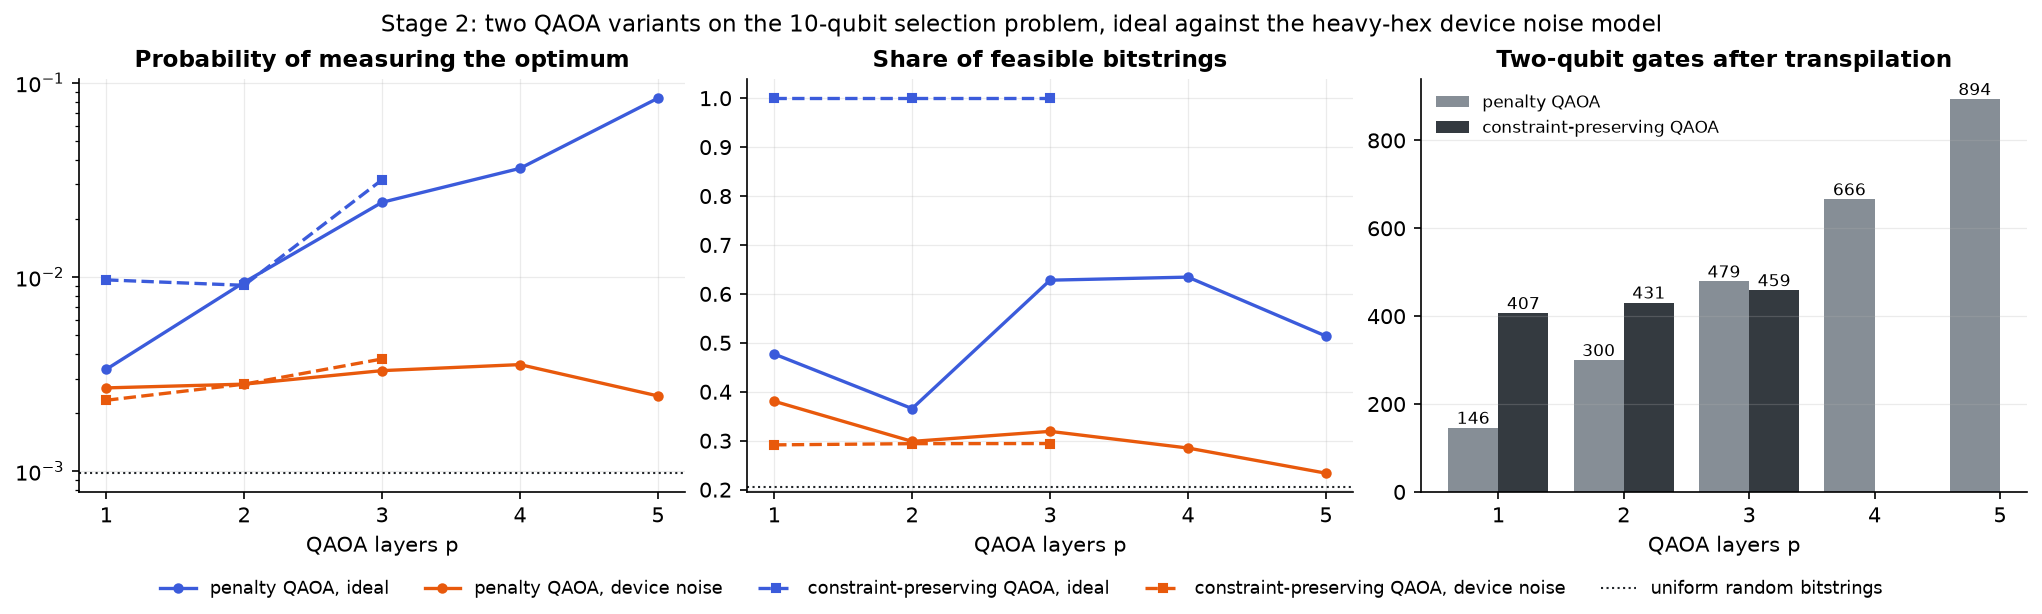

In [13]:
display(Image(filename=str(out / "results" / "figures" / "stage2_qaoa.png")))

**Decoding.** Qiskit prints qubit 0 as the rightmost character. The most frequent measured bitstrings at p = 3:

In [14]:
pd.DataFrame(s2["study"][config.QAOA_LAYERS]["ideal_sample"]["top_bitstrings"])[
    ["bitstring_qiskit", "count", "n_selected", "cost", "capacity", "feasible", "value", "is_exact_optimum"]].round(4)

,bitstring_qiskit,count,n_selected,cost,capacity,feasible,value,is_exact_optimum
0,1000101111,182,6,15.0,12.0,True,24.5334,True
1,1111111111,143,10,27.0,22.0,False,26.8701,False
2,1001001111,140,6,15.0,11.0,True,23.9281,False
3,1001101011,138,6,13.0,13.0,True,24.0287,False
4,0001101111,132,6,16.0,13.0,True,23.2951,False
5,1000011111,130,6,15.0,12.0,True,23.3246,False
6,1000111011,128,6,13.0,14.0,True,23.4252,False
7,1001100111,127,6,14.0,11.0,True,23.9890,False
8,1000110111,125,6,14.0,12.0,True,23.3855,False
9,1100001111,125,6,17.0,11.0,True,23.0223,False


In [15]:
selection = s2["selection"]
print("selected bitstring (Qiskit key):", selection["bitstring_qiskit"])
print("decoded, qubit 0 first        :", qubo.key_to_bits(selection["bitstring_qiskit"]).tolist())
print("customers                     :", selection["ids"])
print("objective", round(selection["value"], 6), "| gap to brute force", selection["optimality_gap"],
      "| constraint-preserving QAOA agrees:", selection["constraint_preserving_qaoa_agrees"])

selected bitstring (Qiskit key): 1000101111
decoded, qubit 0 first        : [1, 1, 1, 1, 0, 1, 0, 0, 0, 1]
customers                     : ['C0031', 'C0079', 'C0081', 'C0318', 'C0005', 'C0170']
objective 24.533351 | gap to brute force 0.0 | constraint-preserving QAOA agrees: True


## Stage 3: campaign outcome simulation

One qubit per selected customer, in Stage 1 rank order, each rotated so that P(1) is that customer's probability.

In [16]:
print(stage3.campaign_circuit(s3["probabilities"]).draw(fold=120))
pd.DataFrame({"qubit": range(6), "customer_id": s3["ids"], "probability": s3["probabilities"], "ry_angle": s3["angles"],
              "measured_p1_ideal": s3["headline"]["marginals"], "measured_p1_noisy": s3["noisy"]["marginals"]}).round(5)

          ┌──────────┐  ░ ┌─┐               
   q_0: ──┤ Ry(1.74) ├──░─┤M├───────────────
         ┌┴──────────┴┐ ░ └╥┘┌─┐            
   q_1: ─┤ Ry(1.6948) ├─░──╫─┤M├────────────
         ├────────────┤ ░  ║ └╥┘┌─┐         
   q_2: ─┤ Ry(1.2593) ├─░──╫──╫─┤M├─────────
         ├────────────┤ ░  ║  ║ └╥┘┌─┐      
   q_3: ─┤ Ry(1.0122) ├─░──╫──╫──╫─┤M├──────
        ┌┴────────────┤ ░  ║  ║  ║ └╥┘┌─┐   
   q_4: ┤ Ry(0.90276) ├─░──╫──╫──╫──╫─┤M├───
        ├─────────────┤ ░  ║  ║  ║  ║ └╥┘┌─┐
   q_5: ┤ Ry(0.83644) ├─░──╫──╫──╫──╫──╫─┤M├
        └─────────────┘ ░  ║  ║  ║  ║  ║ └╥┘
meas: 6/═══════════════════╩══╩══╩══╩══╩══╩═
                           0  1  2  3  4  5 


,qubit,customer_id,probability,ry_angle,measured_p1_ideal,measured_p1_noisy
0,0,C0031,0.58419,1.73999,0.58414,0.57623
1,1,C0079,0.56183,1.69478,0.56192,0.55402
2,2,C0081,0.34678,1.25934,0.34661,0.34421
3,3,C0318,0.23500,1.01219,0.23523,0.23627
4,4,C0005,0.19028,0.90276,0.19015,0.19205
5,5,C0170,0.16495,0.83644,0.16434,0.16891


In [17]:
rows = [("exact (Poisson-binomial)", s3["exact"], 0.0),
        ("statevector", s3["statevector"]["estimate"], s3["statevector"]["error"]),
        (f"noiseless, {s3['headline']['shots']:,} shots (submitted)", s3["headline"]["estimate"], s3["headline"]["error"]),
        (f"noiseless, {s3['ideal_shots']['shots']:,} shots", s3["ideal_shots"]["estimate"], s3["ideal_shots"]["error"]),
        ("noisy, unmitigated", s3["noisy"]["estimate"], s3["noisy"]["error"]),
        ("noisy, readout mitigated", s3["mitigated"]["estimate"], s3["mitigated"]["error"]),
        ("counter circuit, noiseless", s3["counter"]["estimate"], s3["counter"]["error"]),
        ("Monte Carlo", s3["monte_carlo"]["estimate"], s3["monte_carlo"]["error"])]
pd.DataFrame(rows, columns=["estimate of P(at least 3)", "value", "error against exact"]).round(6)

,estimate of P(at least 3),value,error against exact
0,exact (Poisson-binomial),0.338495,0.000000
1,statevector,0.338495,0.000000
2,"noiseless, 1,048,576 shots (submitted)",0.338246,-0.000249
3,"noiseless, 32,768 shots",0.341522,0.003027
4,"noisy, unmitigated",0.336609,-0.001886
5,"noisy, readout mitigated",0.341186,0.002691
6,"counter circuit, noiseless",0.339233,0.000738
7,Monte Carlo,0.338159,-0.000336


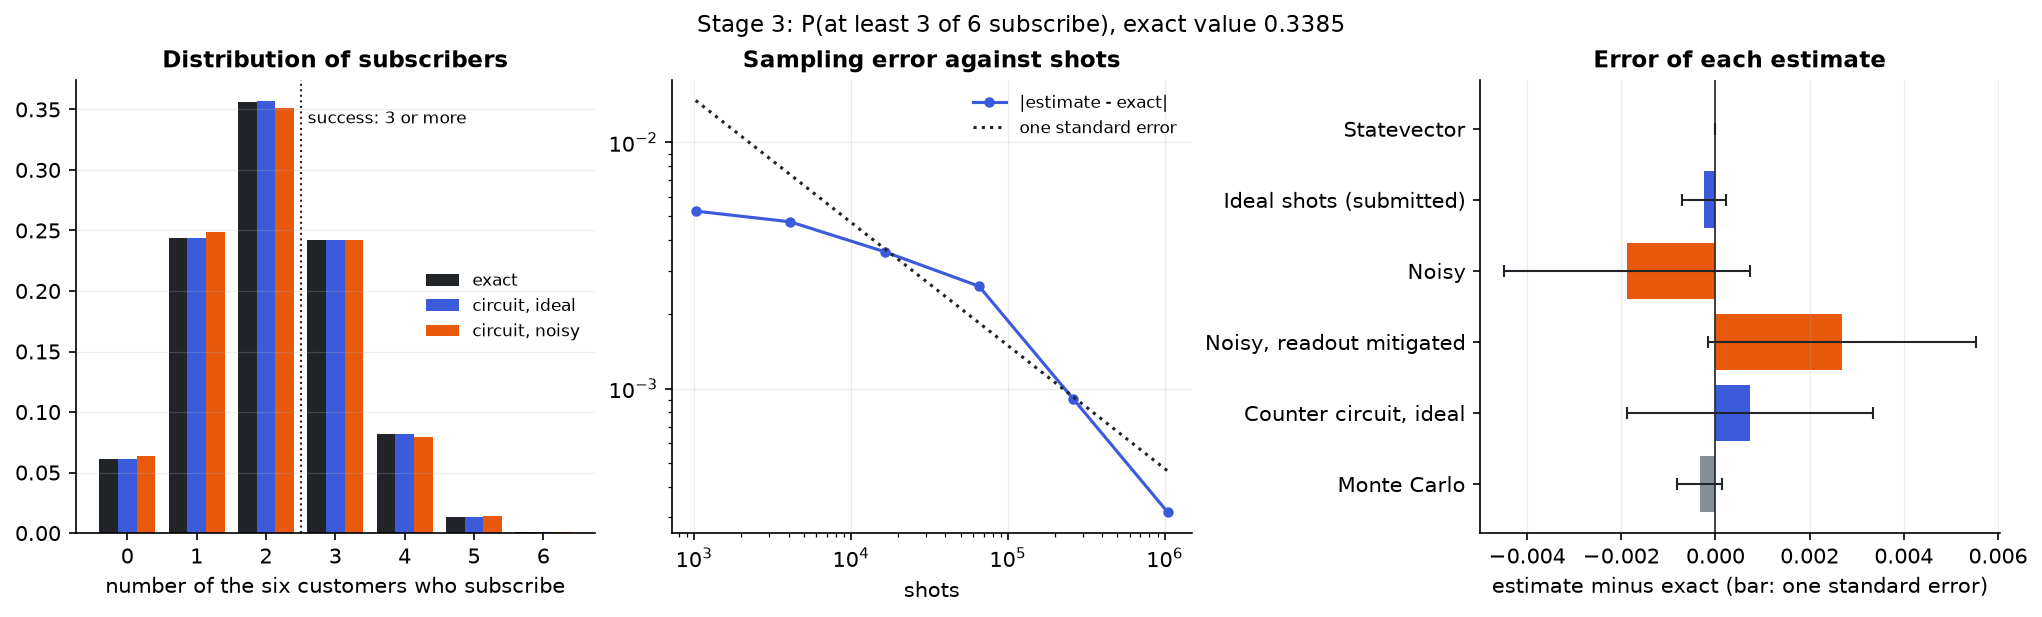

In [18]:
display(Image(filename=str(out / "results" / "figures" / "stage3_simulation.png")))

## Error propagation

The Stage 1 model is refitted on bootstrap resamples of the training rows, and each set of probabilities is pushed through Stages 2 and 3.

top-10 overlap with the submitted candidates (mean): 5.055
same six still optimal (candidates fixed): 0.005
P(at least 3), same six customers: {'mean': 0.1133, 'sd': 0.088, 'p05': 0.0343, 'p50': 0.0879, 'p95': 0.2588}
submitted value: 0.3385 | delta-method sd: 0.1238


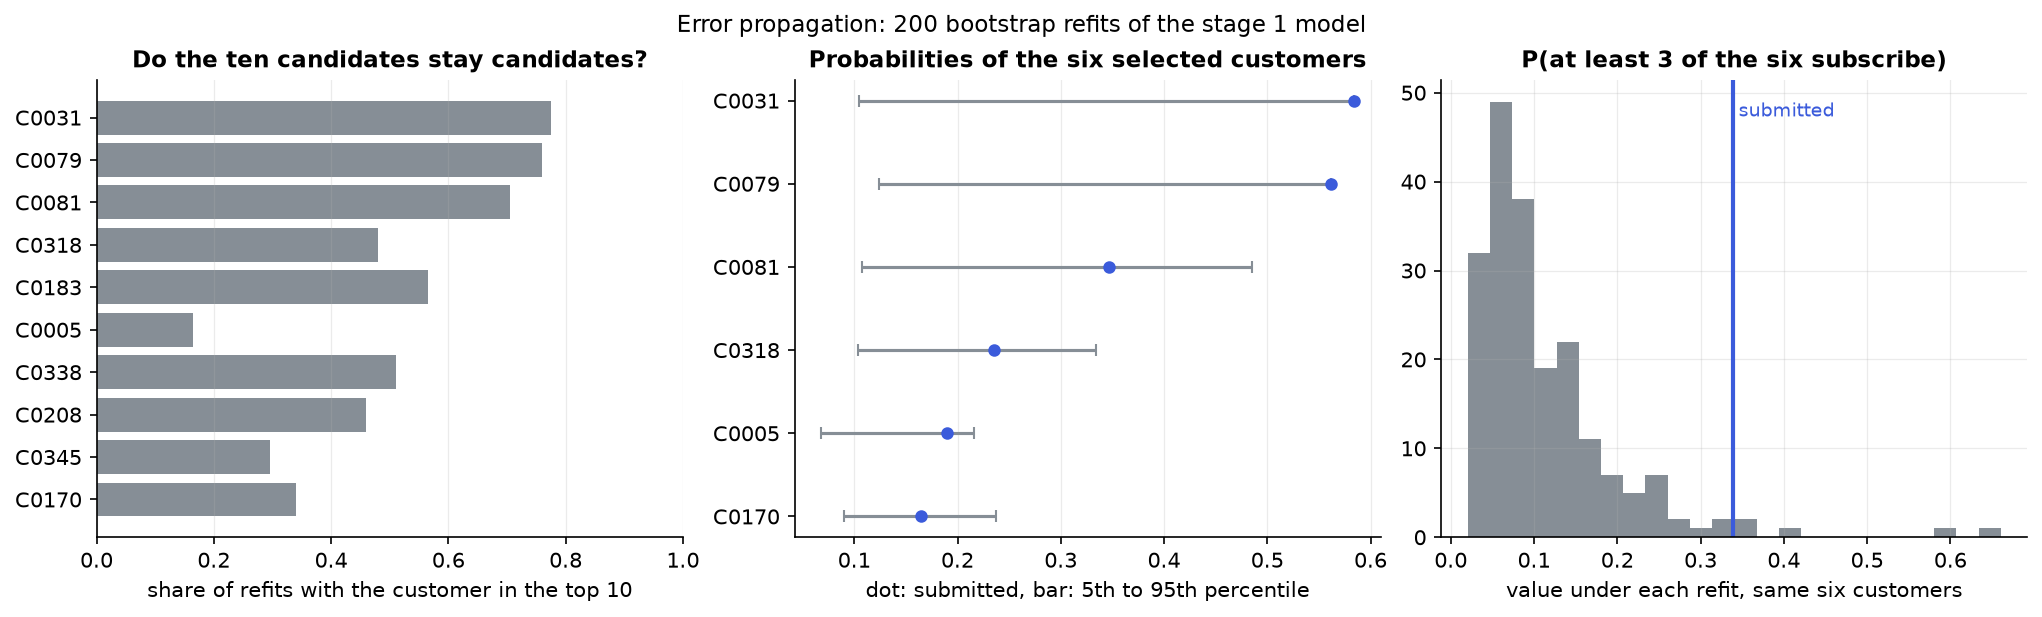

In [19]:
print("top-10 overlap with the submitted candidates (mean):", prop["top10"]["mean_overlap_with_submitted_top10"])
print("same six still optimal (candidates fixed):", prop["stage2"]["fixed_candidates_same_selection_frequency"])
print("P(at least 3), same six customers:", {k: round(v, 4) for k, v in prop["stage3"]["fixed_six"].items()})
print("submitted value:", round(prop["stage3"]["submitted_exact"], 4), "| delta-method sd:", round(prop["stage3"]["delta_method_sd"], 4))
display(Image(filename=str(out / "results" / "figures" / "error_propagation.png")))

## Check against the committed result files

The run above must reproduce the files at the repository root exactly.

In [20]:
names = ["stage1_predictions.csv", "stage2_selection.csv", "stage2_selection.json", "stage3_simulation.csv", "stage3_simulation.json"]
for name in names:
    same = (out / name).read_bytes() == (ROOT / name).read_bytes()
    print(f"{name:28s} identical to the committed file: {same}")
    assert same
shutil.rmtree(out)

stage1_predictions.csv       identical to the committed file: True
stage2_selection.csv         identical to the committed file: True
stage2_selection.json        identical to the committed file: True
stage3_simulation.csv        identical to the committed file: True
stage3_simulation.json       identical to the committed file: True


## Beyond the brief

Three studies built on the committed stage files (README section 11). They read the six selected customers and their Stage 1 probabilities and never write to the stage files. The run goes to a scratch folder and is compared with the committed extension files.

[   0.0s] six customers C0031,C0079,C0081,C0318,C0005,C0170, success = at least 3


[   0.2s] correlated customers: rho 0.0 -> 0.3385, rho 0.1 -> 0.3509, rho 0.2 -> 0.3605, rho 0.3 -> 0.3674, rho 0.5 -> 0.3735

[  65.1s] amplitude estimation: error slope -1.05 (direct sampling -0.50), RMSE 0.00078 against 0.00513 at 8512 applications; on the noise model 0.1646 against 0.0064


[  98.2s] FakeTorino: stage 3 unmitigated 0.3424, mitigated 0.3391 (exact 0.3385)


[  98.2s] FakeBrisbane: stage 3 unmitigated 0.3429, mitigated 0.3390 (exact 0.3385)


[  98.7s] files written to notebook_run_extensions/results/extensions


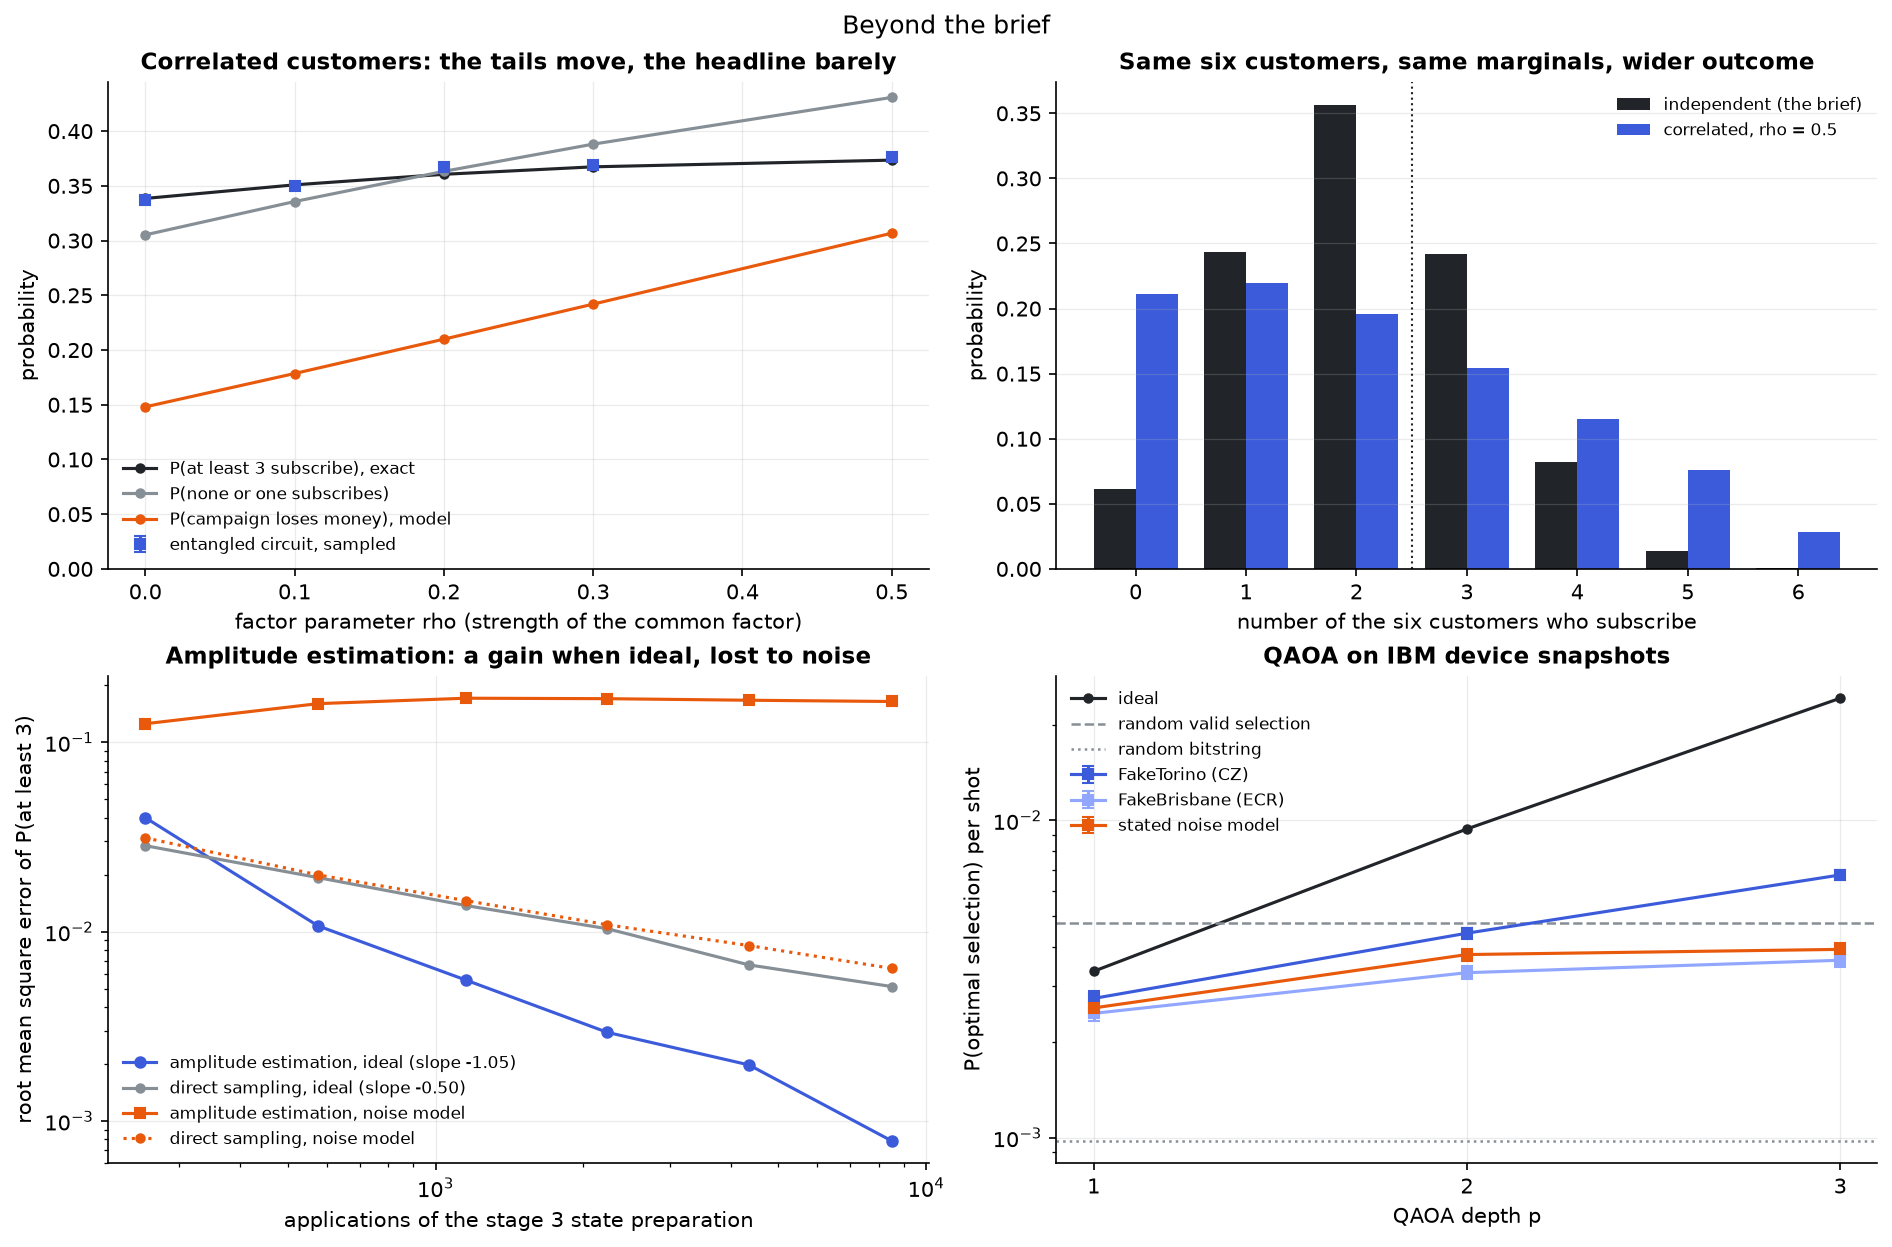

In [21]:
import run_extensions
from campaign import correlated, amplitude

ext_out = Path("notebook_run_extensions")
ext = run_extensions.main(ROOT, ext_out, make_figures=True)
display(Image(filename=str(ext_out / "results" / "figures" / "beyond_the_brief.png")))

### Correlated customers

The entangled circuit: a three-qubit market factor in superposition controls one rotation per customer. Every customer keeps their Stage 1 probability; only the dependence changes.

In [22]:
given = run_extensions.inputs(ROOT)
print(correlated.correlated_circuit(given["probabilities"], 0.3, config.FACTOR_QUBITS).draw(fold=120))
rows = [{"rho": s["rho"], "P(at least 3) exact": s["exact"], "circuit, state vector": s["statevector"],
         "circuit, sampled": s["sampled"]["estimate"], "P(none or one)": s["probability_none_or_one"],
         "P(loss)": s["revenue"]["probability_of_loss"], "expected net value": s["revenue"]["expected_net_value"],
         "sd of net value": s["revenue"]["standard_deviation"]} for s in ext["correlated"]["scenarios"]]
display(pd.DataFrame(rows).round(4))

            ┌───┐┌─────────────────────────────────────────────────────────────────┐»
  factor_0: ┤ H ├┤1                                                                ├»
            ├───┤│                                                                 │»
  factor_1: ┤ H ├┤2                                                                ├»
            ├───┤│  Ucry(0.98965,1.3091,1.5155,1.6884,1.8508,2.0172,2.2071,2.4824) │»
  factor_2: ┤ H ├┤3                                                                ├»
            └───┘│                                                                 │»
customer_0: ─────┤0                                                                ├»
                 └─────────────────────────────────────────────────────────────────┘»
customer_1: ────────────────────────────────────────────────────────────────────────»
                                                                                    »
customer_2: ──────────────────────────────────────────

,rho,P(at least 3) exact,"circuit, state vector","circuit, sampled",P(none or one),P(loss),expected net value,sd of net value
0,0.0,0.3385,0.3385,0.3371,0.3052,0.1481,24.5334,21.4990
1,0.1,0.3509,0.3509,0.3501,0.3356,0.1785,24.5334,23.8594
2,0.2,0.3605,0.3605,0.3671,0.3633,0.2099,24.5334,26.1421
3,0.3,0.3674,0.3674,0.3686,0.3881,0.2419,24.5334,28.3703
4,0.5,0.3735,0.3735,0.3762,0.4308,0.3068,24.5334,32.7189


### Amplitude estimation

After k Grover steps the probability of a good outcome is sin^2((2k + 1) phi). The cell checks that on the state vector, then shows the error against the number of state preparations on the ideal simulator and on the noise model, where the amplified signal is lost.

In [23]:
p6, exact6 = given["probabilities"], ext["amplitude"]["exact"]
for k in (0, 1, 2, 4, 8):
    print(k, round(amplitude.good_probability_statevector(p6, 3, k), 10), round(amplitude.good_probability_theory(exact6, k), 10))
display(pd.DataFrame(ext["amplitude"]["schedules"])[["grover_powers", "applications_of_A", "rmse", "direct_sampling_rmse_measured",
        "error_ratio_direct_over_amplitude_estimation", "noisy_rmse", "noisy_direct_sampling_rmse_measured"]].round(5))
print("fitted slope, ideal simulator:", round(ext["amplitude"]["fitted_slope_log_rmse_vs_log_cost"], 3),
      "| direct sampling:", round(ext["amplitude"]["fitted_slope_direct_sampling_measured"], 3))
display(pd.DataFrame(ext["amplitude"]["noisy"])[["power", "two_qubit_gates_transpiled", "good_probability_ideal", "good_probability_noisy"]].round(4))

0 0.338494913 0.338494913
1 0.9171123582 0.9171123582
2 0.0013589975 0.0013589975
4 0.4097884029 0.4097884029
8 0.8189397935 0.8189397935


,grover_powers,applications_of_A,rmse,direct_sampling_rmse_measured,error_ratio_direct_over_amplitude_estimation,noisy_rmse,noisy_direct_sampling_rmse_measured
0,"[0, 1]",256,0.04008,0.02849,0.71088,0.12555,0.03133
1,"[0, 1, 2]",576,0.01074,0.01932,1.79924,0.16031,0.01997
2,"[0, 1, 2, 4]",1152,0.00556,0.01376,2.47528,0.17128,0.01461
3,"[0, 1, 2, 4, 8]",2240,0.00294,0.01037,3.52827,0.17030,0.01088
4,"[0, 1, 2, 4, 8, 16]",4352,0.00198,0.00668,3.37510,0.16712,0.00845
5,"[0, 1, 2, 4, 8, 16, 32]",8512,0.00078,0.00513,6.53989,0.16458,0.00640


fitted slope, ideal simulator: -1.051 | direct sampling: -0.496


,power,two_qubit_gates_transpiled,good_probability_ideal,good_probability_noisy
0,0,0,0.3385,0.3329
1,1,214,0.9171,0.6105
2,2,486,0.0014,0.5826
3,4,1149,0.4098,0.6361
4,8,2364,0.8189,0.6388
5,16,4787,0.9950,0.6441
6,32,9706,0.2127,0.6404


### IBM device snapshots

The Stage 3 circuit and the trained QAOA circuits on the calibration data of two real IBM processors (simulated, no account needed).

In [24]:
for backend in ext["ibm"]["backends"]:
    s = backend["stage3"]
    print(backend["snapshot"], "| stage 3 unmitigated", round(s["unmitigated"]["estimate"], 5), "| mitigated", round(s["mitigated"]["estimate"], 5),
          "+-", round(s["mitigated"]["standard_error"], 5), "| exact", round(s["exact"], 5))
    display(pd.DataFrame(backend["stage2"])[["layers", "physical_qubits_used", "depth_transpiled", "two_qubit_gates_transpiled", "swap_count",
            "p_optimal_ideal", "p_optimal", "p_optimal_standard_error", "right_size_fraction", "p_optimal_given_right_size"]].round(5))
print("stated noise model, same shots:")
display(pd.DataFrame(ext["ibm"]["stated_noise_model"]["stage2"])[["layers", "depth_transpiled", "two_qubit_gates_transpiled",
        "p_optimal_ideal", "p_optimal", "p_optimal_standard_error", "right_size_fraction", "p_optimal_given_right_size"]].round(5))
print("references:", ext["ibm"]["uniform_reference"])
for name in ["correlated_customers.json", "amplitude_estimation.json", "ibm_snapshots.json"]:
    same = (ext_out / "results" / "extensions" / name).read_bytes() == (ROOT / "results" / "extensions" / name).read_bytes()
    print(f"{name:28s} identical to the committed file: {same}")
    assert same
shutil.rmtree(ext_out)

FakeTorino | stage 3 unmitigated 0.34244 | mitigated 0.3391 +- 0.00267 | exact 0.33849


,layers,physical_qubits_used,depth_transpiled,two_qubit_gates_transpiled,swap_count,p_optimal_ideal,p_optimal,p_optimal_standard_error,right_size_fraction,p_optimal_given_right_size
0,1,10,262,144,33,0.00334,0.00275,0.00014,0.40122,0.00685
1,2,10,384,299,72,0.00939,0.00441,0.00018,0.30895,0.01427
2,3,10,554,452,111,0.02427,0.00673,0.00023,0.36892,0.01824


FakeBrisbane | stage 3 unmitigated 0.34293 | mitigated 0.33896 +- 0.00272 | exact 0.33849


,layers,physical_qubits_used,depth_transpiled,two_qubit_gates_transpiled,swap_count,p_optimal_ideal,p_optimal,p_optimal_standard_error,right_size_fraction,p_optimal_given_right_size
0,1,10,378,144,16,0.00334,0.00246,0.00014,0.38712,0.00637
1,2,10,655,315,58,0.00939,0.00331,0.00016,0.30176,0.01097
2,3,10,933,455,64,0.02427,0.00362,0.00017,0.32464,0.01116


stated noise model, same shots:


,layers,depth_transpiled,two_qubit_gates_transpiled,p_optimal_ideal,p_optimal,p_optimal_standard_error,right_size_fraction,p_optimal_given_right_size
0,1,296,146,0.00334,0.00256,0.00014,0.38422,0.00667
1,2,490,300,0.00939,0.00378,0.00017,0.30453,0.01240
2,3,721,479,0.02427,0.00392,0.00017,0.31904,0.01229


references: {'p_optimal_random_bitstring': 0.0009765625, 'p_optimal_random_valid_selection': 0.004761904761904762, 'right_size_fraction_random_bitstring': 0.205078125, 'valid_selections': 210}
correlated_customers.json    identical to the committed file: True
amplitude_estimation.json    identical to the committed file: True
ibm_snapshots.json           identical to the committed file: True
